## Get Housing price dataset

In [1]:
import pandas as pd
df_house = pd.read_csv('/Users/phatpeso/Desktop/Phat/Python/Data Mining/data/raw/self_study/Housing.csv')
display(df_house.head(10))
display(df_house.info())

,price,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,13300000,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,12250000,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,12250000,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,12215000,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,11410000,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished
5,10850000,7500,3,3,1,yes,no,yes,no,yes,2,yes,semi-furnished
6,10150000,8580,4,3,4,yes,no,no,no,yes,2,yes,semi-furnished
7,10150000,16200,5,3,2,yes,no,no,no,no,0,no,unfurnished
8,9870000,8100,4,1,2,yes,yes,yes,no,yes,2,yes,furnished
9,9800000,5750,3,2,4,yes,yes,no,no,yes,1,yes,unfurnished


<class 'pandas.DataFrame'>
RangeIndex: 545 entries, 0 to 544
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   price             545 non-null    int64
 1   area              545 non-null    int64
 2   bedrooms          545 non-null    int64
 3   bathrooms         545 non-null    int64
 4   stories           545 non-null    int64
 5   mainroad          545 non-null    str  
 6   guestroom         545 non-null    str  
 7   basement          545 non-null    str  
 8   hotwaterheating   545 non-null    str  
 9   airconditioning   545 non-null    str  
 10  parking           545 non-null    int64
 11  prefarea          545 non-null    str  
 12  furnishingstatus  545 non-null    str  
dtypes: int64(6), str(7)
memory usage: 55.5 KB


None

## Preprocessing data

In [2]:
x = df_house.drop('price',axis= 1)
y = df_house['price']
print('x df: ')
display(x.head(5))
print('y df: ')
display(y.head(5))

x df: 


,area,bedrooms,bathrooms,stories,mainroad,guestroom,basement,hotwaterheating,airconditioning,parking,prefarea,furnishingstatus
0,7420,4,2,3,yes,no,no,no,yes,2,yes,furnished
1,8960,4,4,4,yes,no,no,no,yes,3,no,furnished
2,9960,3,2,2,yes,no,yes,no,no,2,yes,semi-furnished
3,7500,4,2,2,yes,no,yes,no,yes,3,yes,furnished
4,7420,4,1,2,yes,yes,yes,no,yes,2,no,furnished


y df: 


0    13300000
1    12250000
2    12250000
3    12215000
4    11410000
Name: price, dtype: int64

## Using sklearn to spilt dataset into Training and Test sets

In [3]:
from sklearn.model_selection import train_test_split
x_encoded = pd.get_dummies(x, drop_first=True)
x_train,x_test,y_train,y_test = train_test_split(x_encoded,y,test_size =0.20,random_state = 42)

### Choosing Linear regression model and fiting model

In [4]:
from sklearn import linear_model
lr = linear_model.LinearRegression() ## Hồi quy tuyến tính 
lr.fit(x_train,y_train)
print("Huấn luyện mô hình thành công!")
display(lr)

Huấn luyện mô hình thành công!


,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](13,)","[ 235.97, 76778.7 ,1094444.79,..., 629890.57,-126881.82,-413645.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['area','bedrooms','bathrooms',...,'prefarea_yes', 'furnishingstatus_semi-furnished','furnishingstatus_unfurnished']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,2.6e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


### Using model (lr) to predict new prices from test set

In [5]:
y_pred = lr.predict(x_test)

### Evaluation of predicted prices

In [7]:
from sklearn import metrics
import numpy as np

# 1. MAE - Sai số tuyệt đối trung bình
print('MAE: ', metrics.mean_absolute_error(y_test, y_pred))

# 2. MSE - Sai số bình phương trung bình
mse = metrics.mean_squared_error(y_test, y_pred)
print('MSE: ', mse)

# 3. RMSE - Căn bậc hai của MSE (Thay thế cho code bị lỗi)
print('RMSE: ', np.sqrt(mse))

# 4. R-squared - Hệ số xác định (Mô hình giải thích được bao nhiêu % dữ liệu)
print('R_squared: ', metrics.r2_score(y_test, y_pred))

MAE:  970043.4039201637
MSE:  1754318687330.663
RMSE:  1324506.9600914384
R_squared:  0.6529242642153186


In [9]:
from sklearn.metrics import mean_squared_error as MSE
from sklearn.metrics import mean_absolute_error as MAE
from sklearn.metrics import r2_score
import numpy as np # Import thêm thư viện numpy để tính toán

print('MAE:', MAE(y_test, y_pred))

# Tính MSE trước, sau đó dùng np.sqrt() để tính RMSE
mse_value = MSE(y_test, y_pred)
print('RMSE:', np.sqrt(mse_value)) 
print('MSE:', mse_value)

print('R_squared:', r2_score(y_test, y_pred))

MAE: 970043.4039201637
RMSE: 1324506.9600914384
MSE: 1754318687330.663
R_squared: 0.6529242642153186


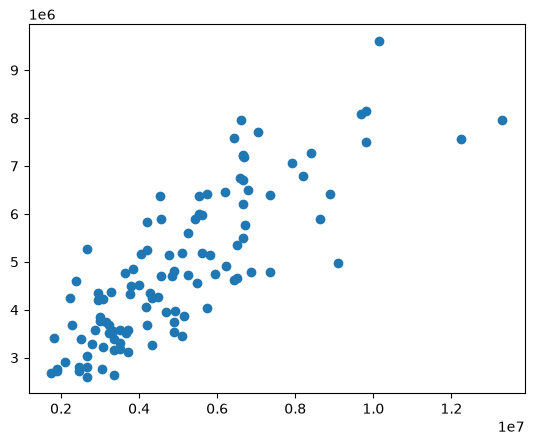

In [10]:
import matplotlib.pyplot as plt
plt.scatter(y_test,y_pred)
plt.show()

### Test Random Forest (SOTA)

In [11]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error as MAE, mean_squared_error as MSE, r2_score
import numpy as np

# 1. Khởi tạo và huấn luyện mô hình Random Forest
rf = RandomForestRegressor(random_state=42)
rf.fit(x_train, y_train)

# 2. Yêu cầu mô hình đưa ra dự đoán trên tập kiểm thử
y_pred_rf = rf.predict(x_test)

# 3. Tính toán và in ra các chỉ số đánh giá
print('--- Kết quả mô hình Random Forest ---')
print('MAE:', MAE(y_test, y_pred_rf))
print('RMSE:', np.sqrt(MSE(y_test, y_pred_rf)))
print('R_squared:', r2_score(y_test, y_pred_rf))

--- Kết quả mô hình Random Forest ---
MAE: 1021546.0353211008
RMSE: 1400565.9728553821
R_squared: 0.611918531405699
